# California housing — EDA, probability and statistical inference
This notebook retains the original distributions, Central Limit Theorem (CLT), confidence intervals, Law of Large Numbers (LLN), one-/two-sample z and t tests, F test and chi-square topics. The calculations distinguish simulation lessons from observational comparisons.

Rows describe geographic housing aggregates, not individual house transactions. `median_house_value` is the area's median; its arithmetic mean across rows is a mean of area medians, not the median price of all California houses. All analyses remain descriptive/statistical; no predictive model is fitted.


## 1. Load and audit the data


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import scipy.stats as sts
from IPython.display import display
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 20)
SEED = 42
ALPHA = 0.05  # Significance level; 95% confidence = 1 - alpha.

DATA_PATH = next((candidate for location in (Path.cwd(), *Path.cwd().parents)
                  for candidate in (location / "housing_dataset/housing.csv",
                                    location / "statistics/housing_data_analysis/housing_dataset/housing.csv")
                  if candidate.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Start Jupyter from the repository or housing_data_analysis folder.")
raw_data = pd.read_csv(DATA_PATH)
required = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
            "population", "households", "median_income", "median_house_value", "ocean_proximity"]
if set(required) - set(raw_data):
    raise ValueError("Housing source does not have the expected schema")
display(raw_data.head())
schema = pd.DataFrame({"dtype": raw_data.dtypes.astype(str), "missing": raw_data.isna().sum(),
                      "missing_percent": raw_data.isna().mean() * 100, "unique": raw_data.nunique()})
display(schema)
print("Source shape:", raw_data.shape, "exact duplicates:", raw_data.duplicated().sum())


Matplotlib is building the font cache; this may take a moment.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


,dtype,missing,missing_percent,unique
longitude,float64,0,0.000000,844
latitude,float64,0,0.000000,862
housing_median_age,float64,0,0.000000,52
total_rooms,float64,0,0.000000,5926
total_bedrooms,float64,207,1.002907,1923
population,float64,0,0.000000,3888
households,float64,0,0.000000,1815
median_income,float64,0,0.000000,12928
median_house_value,float64,0,0.000000,3842
ocean_proximity,str,0,0.000000,5


Source shape: (20640, 10) exact duplicates: 0


## 2. Deterministic cleaning and analysis-specific missingness
Preserve the CSV and raw frame. Remove only exact repeated records, coerce nonfinite numeric values to missing, and audit impossible quantities. Do not replace missing bedrooms with a global median for statistical tests: each analysis reports the records available for the variables it uses.

Retain valid extremes and the top-valued records. The repeated upper value is flagged as a possible recording ceiling; analyses describe the recorded values and cannot recover prices above that ceiling.


In [2]:
data = raw_data[required].drop_duplicates().copy()
numeric_columns = [column for column in required if column != "ocean_proximity"]
for column in numeric_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
data["ocean_proximity"] = data.ocean_proximity.astype("string").str.strip().str.upper()
domain_flags = pd.DataFrame(index=data.index)
domain_flags["longitude"] = data.longitude.notna() & ~data.longitude.between(-180, 180)
domain_flags["latitude"] = data.latitude.notna() & ~data.latitude.between(-90, 90)
for column in ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "median_house_value"]:
    domain_flags[column] = data[column].notna() & (data[column] <= 0)
for column in domain_flags:
    data.loc[domain_flags[column], column] = np.nan
data = data.reset_index(drop=True)
analysis = data.dropna(subset=["median_house_value", "median_income", "ocean_proximity"]).copy()
median_house_value = analysis.median_house_value.to_numpy()
population_mean = median_house_value.mean()  # Empirical reference for simulation only.
population_std = median_house_value.std(ddof=0)
top_recorded_value = float(analysis.median_house_value.max())
cap_count = int(analysis.median_house_value.eq(top_recorded_value).sum())
cleaning_summary = {"source_rows": len(raw_data), "retained_rows": len(data), "analysis_rows": len(analysis),
                    "missing_bedrooms": int(data.total_bedrooms.isna().sum()),
                    "invalid_values": int(domain_flags.sum().sum()), "duplicates_removed": len(raw_data) - len(data),
                    "top_recorded_value": top_recorded_value, "top_value_rows": cap_count}
display(pd.Series(cleaning_summary).to_frame("value"))
display(data.describe().T)


,value
source_rows,20640.0
retained_rows,20640.0
analysis_rows,20640.0
missing_bedrooms,207.0
invalid_values,0.0
duplicates_removed,0.0
top_recorded_value,500001.0
top_value_rows,965.0


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


### Observations: cleaning and the recorded ceiling
All **20,640 areas** are retained: no duplicate records or invalid domain values were found. Bedrooms are missing for **207 rows (1.0%)**. Analyses of value/income can use all rows; bedroom summaries show their own available counts, without invented values.

The maximum recorded median value is **$500,001**, repeated in **965 areas (4.68%)**. This is consistent with a possible ceiling and is retained. Results concern the recorded medians, not any unobserved values above that limit.


## 3. Distributions and descriptive group profiles
The original exercise focuses on house values and income. Histograms, boxplots and an income/value scatter show spread, skewness and possible ceilings. Geographic proximity groups have unequal sizes; the tiny ISLAND group needs separate caution.

The original means of households, rooms and bedrooms by proximity are retained as descriptive summaries. They are not frequency counts suitable for a chi-square test.


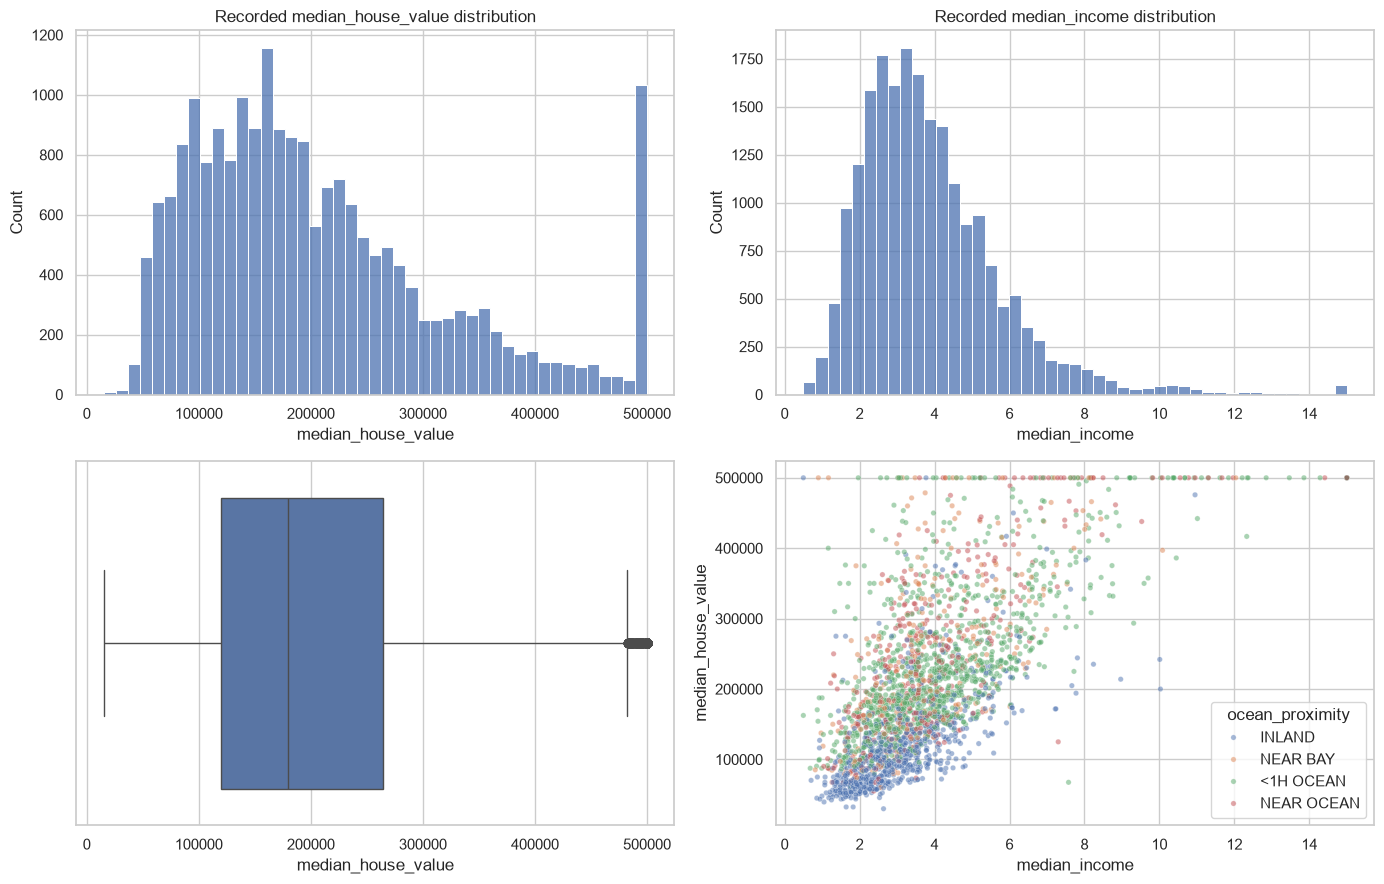

,rows,mean_value,median_value,mean_income,mean_households,mean_rooms,mean_bedrooms,observed_bedrooms
ocean_proximity,,,,,,,,
<1H OCEAN,9136,240084.285464,214850.0,4.230682,517.744965,2628.343586,546.539185,9034
INLAND,6551,124805.392001,108500.0,3.208996,477.447565,2717.742787,533.881619,6496
ISLAND,5,380440.000000,414700.0,2.744420,276.600000,1574.600000,420.400000,5
NEAR BAY,2290,259212.311790,233800.0,4.172885,488.616157,2493.589520,514.182819,2270
NEAR OCEAN,2658,249433.977427,229450.0,4.005785,501.244545,2583.700903,538.615677,2628


,value
mean_value,206855.816909
median_value,179700.000000
std_value,115392.820404
value_skew,0.977692
income_skew,1.646537
income_value_spearman,0.676778


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for column, ax in zip(["median_house_value", "median_income"], axes[0]):
    sns.histplot(data=analysis, x=column, bins=45, ax=ax)
    ax.set_title(f"Recorded {column} distribution")
sns.boxplot(data=analysis, x="median_house_value", ax=axes[1, 0])
sample_plot = analysis.sample(min(2500, len(analysis)), random_state=SEED)
sns.scatterplot(data=sample_plot, x="median_income", y="median_house_value", hue="ocean_proximity", s=15, alpha=.5, ax=axes[1, 1])
plt.tight_layout()
plt.show()
group_profiles = analysis.groupby("ocean_proximity").agg(
    rows=("median_house_value", "size"), mean_value=("median_house_value", "mean"),
    median_value=("median_house_value", "median"), mean_income=("median_income", "mean"),
    mean_households=("households", "mean"), mean_rooms=("total_rooms", "mean"),
    mean_bedrooms=("total_bedrooms", "mean"), observed_bedrooms=("total_bedrooms", "count"))
display(group_profiles)
distribution_summary = {"mean_value": float(population_mean), "median_value": float(np.median(median_house_value)),
                        "std_value": float(population_std), "value_skew": float(sts.skew(median_house_value)),
                        "income_skew": float(sts.skew(analysis.median_income)),
                        "income_value_spearman": float(sts.spearmanr(analysis.median_income, analysis.median_house_value).statistic)}
display(pd.Series(distribution_summary).to_frame("value"))


### Observations: distributions and proximity groups
The mean area median value is **$206,856**, above the median of **$179,700**; value skewness is **0.98** and income skewness **1.65**. Income and recorded value have a positive rank association (Spearman **0.677**), with substantial scatter and an upper-value pile-up.

INLAND averages about **$124,805**, while NEAR BAY and NEAR OCEAN average **$259,212** and **$249,434**. These are unadjusted area-level descriptions, not a causal proximity effect. ISLAND has only **five rows**; its apparently high mean is too sparsely supported for a broad claim.


## 4. Central Limit Theorem: replications versus sample size
Keep the original replication counts 100, 500, 1,000, 5,000 and 10,000 at n = 30. More replications make the simulated distribution smoother; they do not change the distribution of a single n = 30 sample mean.

Then vary n = 5, 30 and 100 at a fixed replication count. Increasing n reduces standard error and usually makes the mean's sampling distribution closer to normal. Sampling with replacement constructs an explicit iid empirical-reference experiment; it is not a new survey of California households.


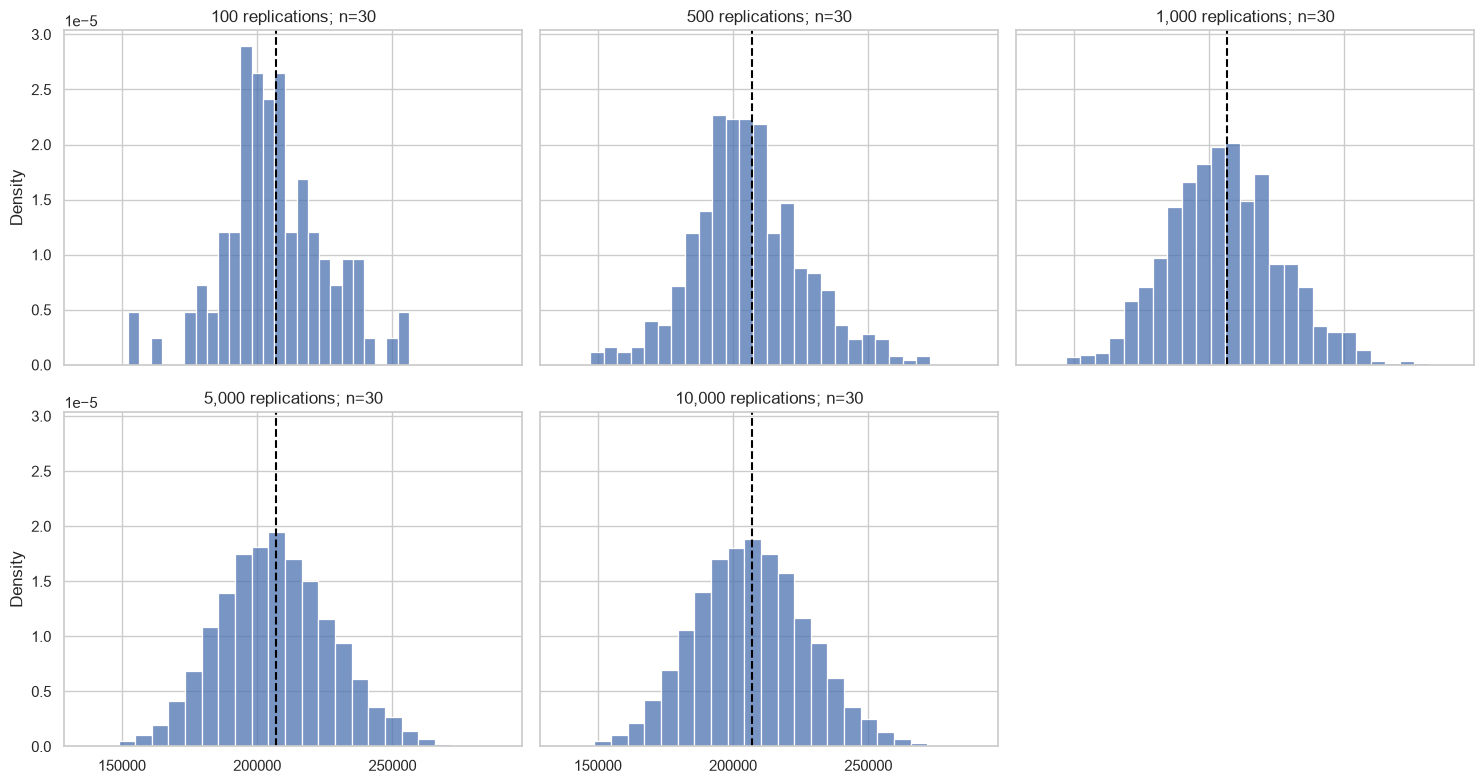

,replications,n,mean_of_means,simulated_sd,theoretical_se
0,100,30,206505.447667,19255.176102,21067.750236
1,500,30,205507.877667,20436.083968,21067.750236
2,1000,30,205794.405667,20852.359205,21067.750236
3,5000,30,206703.332307,20876.993962,21067.750236
4,10000,30,206769.818407,20954.800757,21067.750236


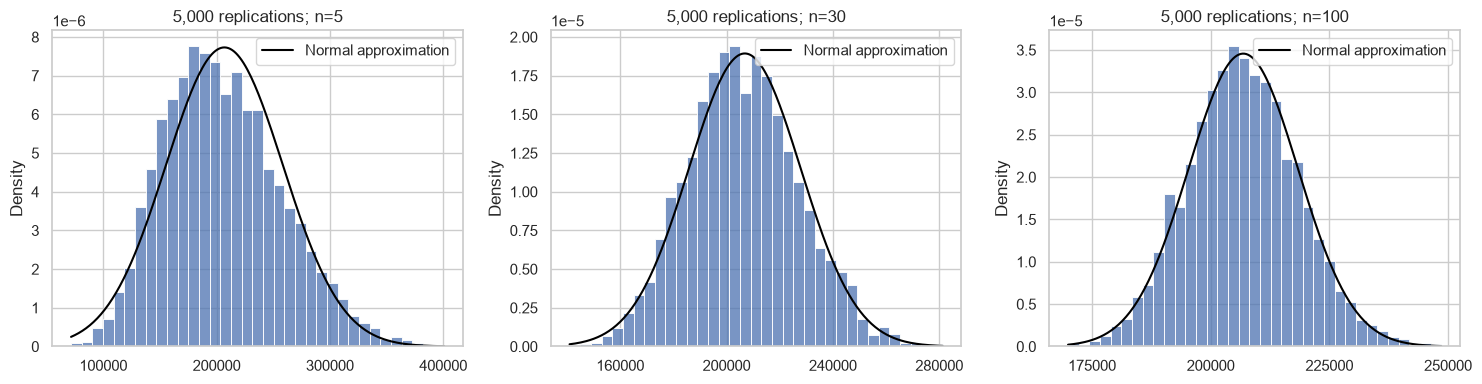

,n,mean_of_means,simulated_sd,theoretical_se,mean_skewness
0,5,205603.718600,51876.472167,51605.238108,0.420724
1,30,206306.567080,20881.723775,21067.750236,0.185255
2,100,206728.941988,11615.733397,11539.282040,0.129350


In [4]:
rng_clt = np.random.default_rng(SEED + 1)
sample_means_n30 = rng_clt.choice(median_house_value, size=(10000, 30), replace=True).mean(axis=1)
replication_records = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, repetitions in zip(axes.flat, [100, 500, 1000, 5000, 10000]):
    means = sample_means_n30[:repetitions]
    sns.histplot(means, bins=25, stat="density", ax=ax)
    ax.axvline(population_mean, color="black", linestyle="--")
    ax.set_title(f"{repetitions:,} replications; n=30")
    ax.xaxis.set_major_locator(MaxNLocator(4))
    replication_records.append({"replications": repetitions, "n": 30, "mean_of_means": means.mean(),
                                "simulated_sd": means.std(ddof=1), "theoretical_se": population_std / np.sqrt(30)})
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()
replication_summary = pd.DataFrame(replication_records)
display(replication_summary)
clt_records = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [5, 30, 100]):
    means = rng_clt.choice(median_house_value, size=(5000, n), replace=True).mean(axis=1)
    expected_se = population_std / np.sqrt(n)
    sns.histplot(means, bins=35, stat="density", ax=ax)
    grid = np.linspace(means.min(), means.max(), 200)
    ax.plot(grid, sts.norm.pdf(grid, loc=population_mean, scale=expected_se), color="black", label="Normal approximation")
    ax.set_title(f"5,000 replications; n={n}")
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.legend()
    clt_records.append({"n": n, "mean_of_means": means.mean(), "simulated_sd": means.std(ddof=1),
                        "theoretical_se": expected_se, "mean_skewness": sts.skew(means)})
plt.tight_layout()
plt.show()
clt_summary = pd.DataFrame(clt_records)
display(clt_summary)


### Observations: CLT
With 5,000 replications, simulated mean standard deviations fall from **$51,876 at n=5** to **$20,882 at n=30** and **$11,616 at n=100**. They track the theoretical sigma/sqrt(n) values. Mean-distribution skewness falls from **0.42** to **0.13**.

At fixed n=30, increasing replications smooths the histogram and stabilizes Monte Carlo estimates; it does not narrow a single sample mean's distribution. The CLT concerns the sampling distribution of a statistic, not a transformation that makes the original housing values normal.


## 5. Confidence intervals at 90%, 95% and 99%
Use actual observations from one simulated sample and `s / sqrt(n)` for its standard error. The confidence level is 1 − alpha, not alpha. The original interval of the mean of many simulated means measured Monte Carlo precision rather than uncertainty from one sample; that calculation is replaced here.

Unknown standard deviation uses a t interval. Larger confidence levels widen the interval for the same observations. Larger n generally narrows it; it need not do so in every realized sequence because the estimated variance also changes.


,n,confidence,sample_mean,lower,upper,width
0,30,0.90,192710.066667,153903.592277,231516.541056,77612.948779
1,30,0.95,192710.066667,145998.931779,239421.201554,93422.269775
2,30,0.99,192710.066667,129756.786949,255663.346385,125906.559436
3,100,0.90,209182.050000,190374.683893,227989.416107,37614.732214
4,100,0.95,209182.050000,186706.686584,231657.413416,44950.726832
5,100,0.99,209182.050000,179432.572715,238931.527285,59498.954570
6,500,0.90,210828.446000,202450.096997,219206.795003,16756.698007
7,500,0.95,210828.446000,200839.333289,220817.558711,19978.225421
8,500,0.99,210828.446000,197682.093381,223974.798619,26292.705238
9,1000,0.90,205187.041000,199246.474361,211127.607639,11881.133278


,interval,replications,coverage
0,t: estimated sigma,1000,0.938
1,z: known empirical sigma,1000,0.946


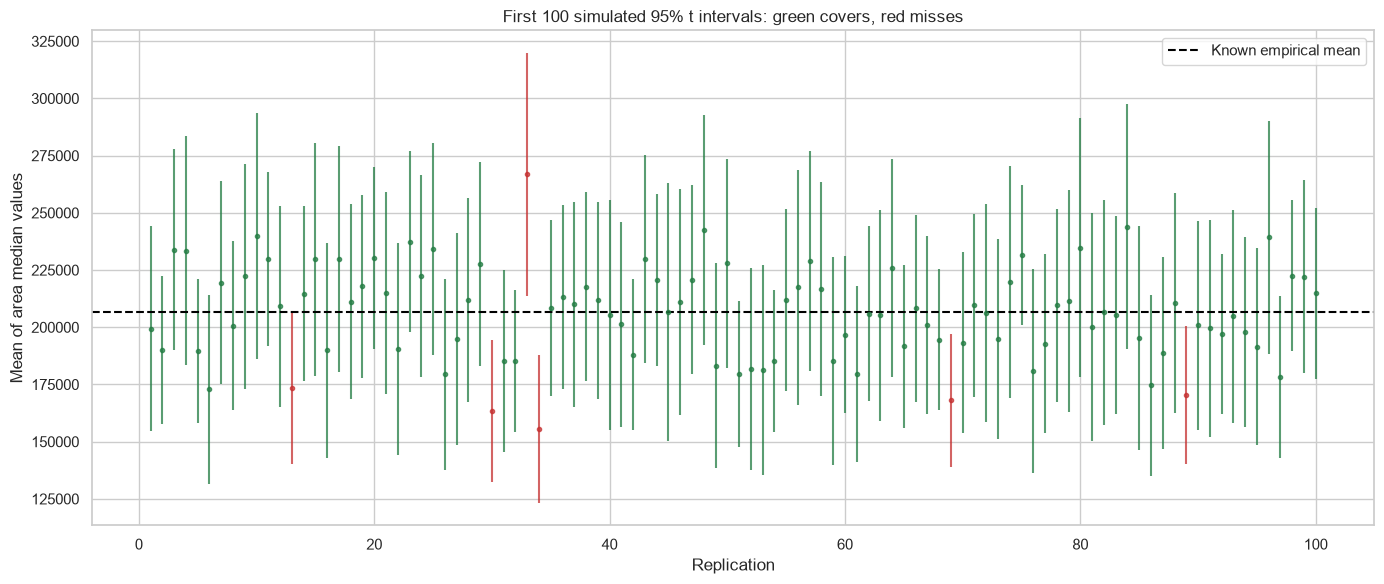

In [5]:
rng_ci = np.random.default_rng(SEED + 2)
single_sample = rng_ci.choice(median_house_value, size=1000, replace=True)
ci_records = []
for n in [30, 100, 500, 1000]:
    sample = single_sample[:n]
    for confidence in [.90, .95, .99]:
        low, high = sts.t.interval(confidence, df=n - 1, loc=sample.mean(), scale=sts.sem(sample))
        ci_records.append({"n": n, "confidence": confidence, "sample_mean": sample.mean(),
                           "lower": low, "upper": high, "width": high - low})
ci_table = pd.DataFrame(ci_records)
display(ci_table)

# Repeated-sampling coverage, with 100 of the intervals shown.
coverage_samples = rng_ci.choice(median_house_value, size=(1000, 30), replace=True)
coverage_means = coverage_samples.mean(axis=1)
half_t = sts.t.ppf(1 - ALPHA / 2, df=29) * coverage_samples.std(axis=1, ddof=1) / np.sqrt(30)
half_z = sts.norm.ppf(1 - ALPHA / 2) * population_std / np.sqrt(30)
covered_t = np.abs(coverage_means - population_mean) <= half_t
covered_z = np.abs(coverage_means - population_mean) <= half_z
coverage_table = pd.DataFrame([
    {"interval": "t: estimated sigma", "replications": 1000, "coverage": covered_t.mean()},
    {"interval": "z: known empirical sigma", "replications": 1000, "coverage": covered_z.mean()},
])
display(coverage_table)
fig, ax = plt.subplots(figsize=(14, 6))
for i in range(100):
    ax.errorbar(i + 1, coverage_means[i], yerr=half_t[i], fmt="o", markersize=3,
                color="#237c43" if covered_t[i] else "#c53030", alpha=.75)
ax.axhline(population_mean, color="black", linestyle="--", label="Known empirical mean")
ax.set(title="First 100 simulated 95% t intervals: green covers, red misses", xlabel="Replication", ylabel="Mean of area median values")
ax.legend()
plt.tight_layout()
plt.show()


### Observations: confidence intervals
For the realized nested sample, the 95% interval is **[$145,999, $239,421] at n=30** and **[$198,106, $212,268] at n=1,000**. Width falls from about **$93,422** to **$14,161**. For a fixed n and observations, 99% intervals are wider than 95%, which are wider than 90%.

Across 1,000 empirical-reference experiments at n=30, coverage is **93.8% for t intervals** and **94.6% for known-sigma z intervals**. Finite-sample approximation and Monte Carlo variation matter; nominal 95% need not equal a realized 95%. A frequentist 95% interval refers to repeated-sampling coverage, not a 95% probability assigned to the fixed mean after observing one interval.


## 6. Law of Large Numbers
Use a single sequence of draws and its running mean. This corrects the original independent fresh samples at every n: a running mean now follows a nested sample path. The panels retain the original horizons of 100, 500, 1,000 and 5,000. Convergence does not require the error to shrink at every step.


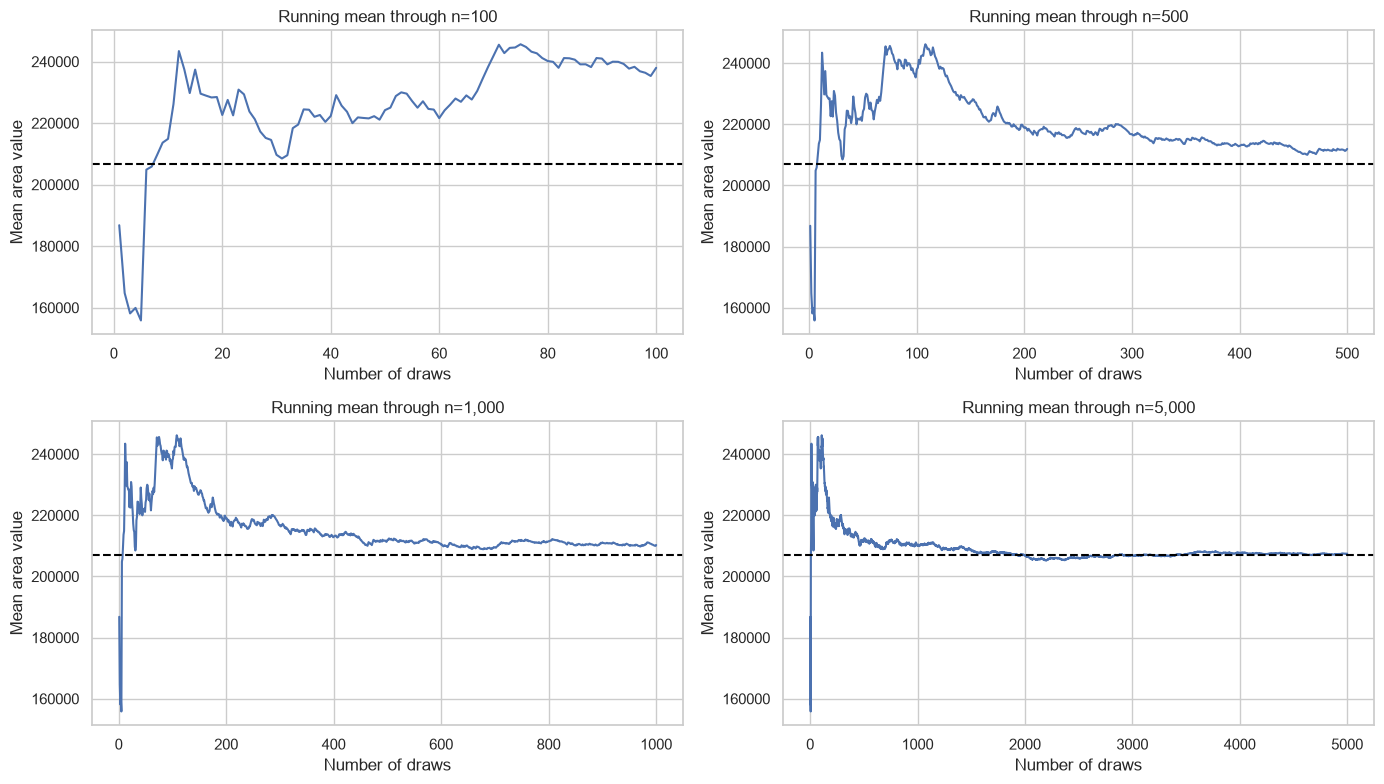

,n,running_mean,absolute_error
0,100,237973.0700,31117.253091
1,500,211940.4620,5084.645091
2,1000,210272.1600,3416.343091
3,5000,207470.2916,614.474691


In [6]:
rng_lln = np.random.default_rng(SEED + 3)
lln_draws = rng_lln.choice(median_house_value, size=5000, replace=True)
running_mean = np.cumsum(lln_draws) / np.arange(1, len(lln_draws) + 1)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, horizon in zip(axes.flat, [100, 500, 1000, 5000]):
    ax.plot(np.arange(1, horizon + 1), running_mean[:horizon])
    ax.axhline(population_mean, color="black", linestyle="--")
    ax.set(title=f"Running mean through n={horizon:,}", xlabel="Number of draws", ylabel="Mean area value")
plt.tight_layout()
plt.show()
lln_summary = pd.DataFrame({"n": [100, 500, 1000, 5000], "running_mean": running_mean[np.array([100, 500, 1000, 5000]) - 1]})
lln_summary["absolute_error"] = (lln_summary.running_mean - population_mean).abs()
display(lln_summary)


### Observations: LLN
The running mean is **$237,973 after 100 draws** and **$207,470 after 5,000**, compared with the empirical mean **$206,856**. Absolute error decreases from about **$31,117** to **$614** at those checkpoints.

The intermediate path still fluctuates. LLN supports long-run convergence under the constructed iid sampling mechanism, not monotonic improvement or a guarantee for an arbitrarily dependent real-world sample.


## Statistical-test practice used here
State the question, observational unit, null/alternative, significance level and test family before interpreting results. Identify whether the quantity is a mean, variance, proportion or categorical association; select a matching test. Report sample sizes, the estimated difference/effect and uncertainty alongside p-values.

Use “reject” or “fail to reject” the null. A large p-value does not prove equality, and a small one is not the probability that the null is true. Keep numerical p-values unrounded for decisions. Welch comparisons do not require equal variances; they still need an independence assumption. Do not use a preliminary normality/variance test as a switch for choosing between pooled and Welch t-tests.

Separate demonstrations generated from an empirical reference from inference about real populations. State missingness, selection, dependence and aggregation limits. Exploratory tests do not establish causation. Correct an explicitly defined family of related comparisons rather than running every ordered pair twice.


## 7. One-sample z and t tests: calibration demonstrations
For z, the empirical reference standard deviation is genuinely known within the simulation. For t, estimate it from each sample and use n−1 degrees of freedom. Both test H0: the simulated sample distribution has mean equal to the empirical reference mean, against a two-sided alternative at alpha = .05.

Reject counts below describe repeated-sampling calibration under a constructed true null. They do not prove a real-world housing mean. Because each replication is a separate calibration experiment, it is not the substantive multiple-testing family later in this notebook.


In [7]:
rng_tests = np.random.default_rng(SEED + 4)
z_samples = rng_tests.choice(median_house_value, size=(1000, 50), replace=True)
z_statistics = (z_samples.mean(axis=1) - population_mean) / (population_std / np.sqrt(50))
z_pvalues = 2 * sts.norm.sf(np.abs(z_statistics))
t_samples = rng_tests.choice(median_house_value, size=(1000, 25), replace=True)
t_manual = (t_samples.mean(axis=1) - population_mean) / (t_samples.std(axis=1, ddof=1) / np.sqrt(25))
t_results = sts.ttest_1samp(t_samples, popmean=population_mean, axis=1)
assert np.allclose(t_manual, t_results.statistic)
calibration_records = []
for name, pvalues in [("One-sample z; n=50", z_pvalues), ("One-sample t; n=25", t_results.pvalue)]:
    rejected = int((pvalues < ALPHA).sum())
    low, high = proportion_confint(rejected, len(pvalues), alpha=ALPHA, method="wilson")
    calibration_records.append({"test": name, "replications": len(pvalues), "rejections": rejected,
                                "rejection_rate": rejected / len(pvalues), "rate_ci_low": low, "rate_ci_high": high})
calibration_summary = pd.DataFrame(calibration_records)
display(calibration_summary)
display(pd.DataFrame({"z_statistic": z_statistics[:5], "z_pvalue": z_pvalues[:5],
                      "t_statistic": t_manual[:5], "t_pvalue": t_results.pvalue[:5]}))


,test,replications,rejections,rejection_rate,rate_ci_low,rate_ci_high
0,One-sample z; n=50,1000,52,0.052,0.039873,0.067556
1,One-sample t; n=25,1000,59,0.059,0.046014,0.075361


,z_statistic,z_pvalue,t_statistic,t_pvalue
0,-1.154101,0.248459,-0.189497,0.851297
1,-0.311769,0.755216,1.261492,0.219255
2,-0.068126,0.945685,-0.958853,0.347193
3,-0.003298,0.997369,0.897985,0.378114
4,-1.080320,0.280000,-0.096158,0.924193


### Observations: one-sample calibration
The true-null simulation rejects **52/1,000 times for z (5.2%)** and **59/1,000 for t (5.9%)**. Their Wilson intervals for rejection frequency both contain the nominal 5% rate. These outcomes are compatible with approximate calibration and Monte Carlo variation; they do not prove exact finite-sample validity.

Most simulated tests fail to reject. That language describes insufficient evidence against the null, not acceptance or proof that two quantities are equal.


## 8. Two-sample z and t comparisons: NEAR BAY versus NEAR OCEAN
H0 is a zero difference in means; no unexplained 9,778.33 offset is subtracted. First retain the z illustration with known empirical group standard deviations. A second z simulation explicitly tests the known empirical difference to check calibration.

Then compare observed groups with Welch's t-test, an estimated difference and a 95% interval. A small-sample demonstration retains the original n=15/n=25 comparison and distinguishes Welch degrees of freedom from the pooled t-test's equal-variance assumption. Neither test removes geographic dependence or makes proximity causal.


In [8]:
bay = analysis.loc[analysis.ocean_proximity.eq("NEAR BAY"), "median_house_value"].to_numpy()
ocean = analysis.loc[analysis.ocean_proximity.eq("NEAR OCEAN"), "median_house_value"].to_numpy()
known_difference = bay.mean() - ocean.mean()
rng_two = np.random.default_rng(SEED + 5)
bay_z = rng_two.choice(bay, size=(100, 30), replace=True)
ocean_z = rng_two.choice(ocean, size=(100, 30), replace=True)
known_se = np.sqrt(bay.var(ddof=0) / 30 + ocean.var(ddof=0) / 30)
z_equal = (bay_z[0].mean() - ocean_z[0].mean()) / known_se
z_calibration = (bay_z.mean(axis=1) - ocean_z.mean(axis=1) - known_difference) / known_se
z_two_summary = {"example_n_per_group": 30, "example_difference": float(bay_z[0].mean() - ocean_z[0].mean()),
                 "z_for_equal_means": float(z_equal), "p_for_equal_means": float(2 * sts.norm.sf(abs(z_equal))),
                 "known_empirical_difference": float(known_difference),
                 "calibration_rejection_rate": float((2 * sts.norm.sf(np.abs(z_calibration)) < ALPHA).mean())}
display(pd.Series(z_two_summary).to_frame("value"))
welch_result = sts.ttest_ind(bay, ocean, equal_var=False)
welch_interval = welch_result.confidence_interval(confidence_level=1 - ALPHA)
pooled_sd = np.sqrt(((len(bay) - 1) * bay.var(ddof=1) + (len(ocean) - 1) * ocean.var(ddof=1)) / (len(bay) + len(ocean) - 2))
welch_summary = {"bay_n": len(bay), "ocean_n": len(ocean), "bay_mean": float(bay.mean()), "ocean_mean": float(ocean.mean()),
                 "mean_difference_bay_minus_ocean": float(known_difference), "ci_low": float(welch_interval.low),
                 "ci_high": float(welch_interval.high), "t": float(welch_result.statistic),
                 "df": float(welch_result.df), "pvalue": float(welch_result.pvalue),
                 "standardized_difference": float(known_difference / pooled_sd)}
display(pd.Series(welch_summary).to_frame("value"))
small_bay = rng_two.choice(bay, size=15, replace=True)
small_ocean = rng_two.choice(ocean, size=25, replace=True)
v1, v2 = small_bay.var(ddof=1) / len(small_bay), small_ocean.var(ddof=1) / len(small_ocean)
manual_df = (v1 + v2)**2 / (v1**2 / (len(small_bay) - 1) + v2**2 / (len(small_ocean) - 1))
manual_t = (small_bay.mean() - small_ocean.mean()) / np.sqrt(v1 + v2)
small_welch = sts.ttest_ind(small_bay, small_ocean, equal_var=False)
small_pooled = sts.ttest_ind(small_bay, small_ocean, equal_var=True)
assert np.isclose(manual_t, small_welch.statistic) and np.isclose(manual_df, small_welch.df)
small_comparison = pd.DataFrame([
    {"method": "Manual Welch", "t": manual_t, "df": manual_df, "pvalue": 2 * sts.t.sf(abs(manual_t), manual_df)},
    {"method": "SciPy Welch", "t": small_welch.statistic, "df": small_welch.df, "pvalue": small_welch.pvalue},
    {"method": "Pooled: requires equal variances", "t": small_pooled.statistic, "df": small_pooled.df, "pvalue": small_pooled.pvalue},
])
display(small_comparison)


,value
example_n_per_group,30.000000
example_difference,13816.600000
z_for_equal_means,0.436390
p_for_equal_means,0.662554
known_empirical_difference,9778.334364
calibration_rejection_rate,0.050000


,value
bay_n,2290.000000
ocean_n,2658.000000
bay_mean,259212.311790
ocean_mean,249433.977427
mean_difference_bay_minus_ocean,9778.334364
ci_low,2922.161922
ci_high,16634.506806
t,2.796018
df,4834.357278
pvalue,0.005194


,method,t,df,pvalue
0,Manual Welch,-0.841289,32.348581,0.406363
1,SciPy Welch,-0.841289,32.348581,0.406363
2,Pooled: requires equal variances,-0.817069,38.000000,0.418983


### Observations: two-sample means
The observed NEAR BAY and NEAR OCEAN groups contain **2,290** and **2,658** areas. BAY minus OCEAN is **$9,778**, with a nominal 95% Welch interval **[$2,922, $16,635]** and raw **p=0.0052**. The standardized difference is only **0.080**, small relative to the within-group spread. The Holm decision is reported with the full family below.

The one simulated n=30-per-group z example has **p=0.663**, while the small n=15/n=25 Welch example has **p=0.406**. These small draws are noisy and do not overturn the observed full-group difference. Manual and SciPy Welch statistics/degrees of freedom match; the pooled result uses a different variance assumption.


## 9. F-test lesson and a robust dispersion comparison
Retain ten n=20/n=30 F-test illustrations. The numerator remains the BAY variance and the denominator OCEAN variance, so degrees of freedom stay attached to the right sample. The two-sided p-value uses both F tails.

The classical F test is sensitive to non-normality; the recorded house values are skewed and show a possible ceiling. Treat its small-sample outputs as a formula lesson. Use median-centered Levene (Brown–Forsythe) as the observational dispersion sensitivity check, not as a prerequisite for choosing Welch.


In [9]:
rng_f = np.random.default_rng(SEED + 6)
f_records = []
for repetition in range(10):
    a = rng_f.choice(bay, size=20, replace=True)
    b = rng_f.choice(ocean, size=30, replace=True)
    ratio = a.var(ddof=1) / b.var(ddof=1)
    p = min(1.0, 2 * min(sts.f.cdf(ratio, 19, 29), sts.f.sf(ratio, 19, 29)))
    f_records.append({"replication": repetition + 1, "variance_ratio_bay_over_ocean": ratio,
                      "df_numerator": 19, "df_denominator": 29, "two_sided_pvalue": p})
f_examples = pd.DataFrame(f_records)
display(f_examples)
brown_forsythe = sts.levene(bay, ocean, center="median")
dispersion_summary = {"bay_sd": float(bay.std(ddof=1)), "ocean_sd": float(ocean.std(ddof=1)),
                      "variance_ratio": float(bay.var(ddof=1) / ocean.var(ddof=1)),
                      "brown_forsythe_statistic": float(brown_forsythe.statistic), "pvalue": float(brown_forsythe.pvalue)}
display(pd.Series(dispersion_summary).to_frame("value"))


,replication,variance_ratio_bay_over_ocean,df_numerator,df_denominator,two_sided_pvalue
0,1,1.346448,19,29,0.459088
1,2,1.350061,19,29,0.455184
2,3,1.693232,19,29,0.195849
3,4,1.692054,19,29,0.196431
4,5,0.758555,19,29,0.536087
5,6,1.313055,19,29,0.496550
6,7,1.293033,19,29,0.520234
7,8,0.766135,19,29,0.551372
8,9,1.212635,19,29,0.624915
9,10,1.294580,19,29,0.518371


,value
bay_sd,122818.537064
ocean_sd,122477.145927
variance_ratio,1.005583
brown_forsythe_statistic,0.554331
pvalue,0.456589


### Observations: dispersion
BAY and OCEAN standard deviations are **$122,819** and **$122,477**, with variance ratio **1.006**. The median-centered dispersion test has **p=0.457**: fail to reject this dispersion null. This does not prove equal variances or equal distributions.

The ten F examples retain their sample-specific numerator/denominator degrees of freedom and use two tails correctly. Their normality assumption is not supported by the skewed, possibly capped source, so they remain a formula demonstration rather than decisive empirical evidence.


## 10. Probability: events, conditioning, Bayes and binomial sampling
Define A = recorded area median value ≥ 250,000 and B = median income ≥ 5 in the CSV's recorded income units. These thresholds are examples, not optimized cutoffs. Calculate marginal, joint and conditional probabilities, then verify Bayes' identity and the law of total probability across all proximity groups.

The observed fraction is exact for this dataset. Wilson intervals illustrate an iid sampling interpretation; geographic dependence and the original data collection limit wider population claims. A binomial example draws ten areas independently with replacement from the empirical reference and asks for at least three high-value areas.


,probability_or_count
P_high_value,0.282413
P_high_income,0.218459
P_joint,0.155475
P_high_value_given_high_income,0.711688
P_high_income_given_high_value,0.550523
bayes_reconstructed_P_high_income_given_high_value,0.550523
high_value_count,5829.000000
wilson_low,0.276312
wilson_high,0.288594
binomial_at_least_3_of_10,0.568980


,rows,high_value_rows,P_high_value_given_group,P_group
ocean_proximity,,,,
<1H OCEAN,9136,3262,0.357049,0.442636
INLAND,6551,354,0.054038,0.317393
ISLAND,5,5,1.000000,0.000242
NEAR BAY,2290,1052,0.459389,0.110950
NEAR OCEAN,2658,1156,0.434913,0.128779


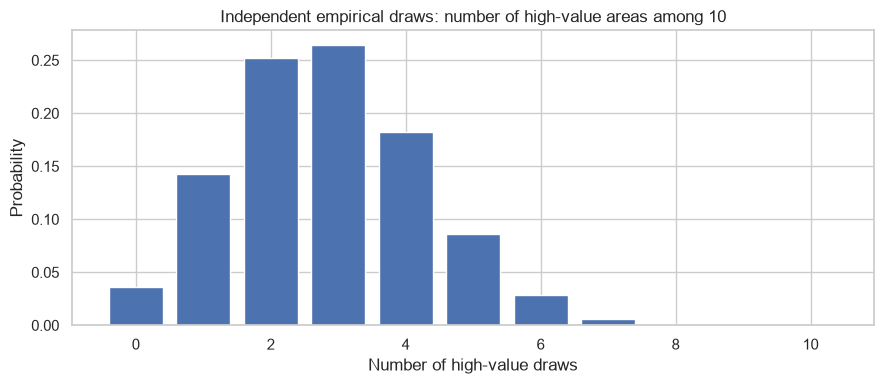

In [10]:
VALUE_THRESHOLD = 250000
INCOME_THRESHOLD = 5
A = analysis.median_house_value.ge(VALUE_THRESHOLD)
B = analysis.median_income.ge(INCOME_THRESHOLD)
probability_summary = {
    "P_high_value": float(A.mean()), "P_high_income": float(B.mean()), "P_joint": float((A & B).mean()),
    "P_high_value_given_high_income": float(A[B].mean()), "P_high_income_given_high_value": float(B[A].mean()),
}
probability_summary["bayes_reconstructed_P_high_income_given_high_value"] = probability_summary["P_high_value_given_high_income"] * probability_summary["P_high_income"] / probability_summary["P_high_value"]
wilson_low, wilson_high = proportion_confint(int(A.sum()), len(A), alpha=ALPHA, method="wilson")
probability_summary.update({"high_value_count": int(A.sum()), "wilson_low": float(wilson_low), "wilson_high": float(wilson_high)})
probability_by_group = analysis.assign(high_value=A).groupby("ocean_proximity").agg(rows=("high_value", "size"), high_value_rows=("high_value", "sum"))
probability_by_group["P_high_value_given_group"] = probability_by_group.high_value_rows / probability_by_group.rows
probability_by_group["P_group"] = probability_by_group.rows / len(analysis)
total_probability = (probability_by_group.P_high_value_given_group * probability_by_group.P_group).sum()
assert np.isclose(total_probability, A.mean())
assert np.isclose(probability_summary["bayes_reconstructed_P_high_income_given_high_value"], probability_summary["P_high_income_given_high_value"])
p_event = A.mean()
binomial_probability = float(sts.binom.sf(2, 10, p_event))
rng_prob = np.random.default_rng(SEED + 7)
binomial_draws = rng_prob.binomial(n=10, p=p_event, size=20000)
probability_summary.update({"binomial_at_least_3_of_10": binomial_probability,
                            "binomial_simulated_at_least_3": float((binomial_draws >= 3).mean()),
                            "total_probability_check": float(total_probability)})
display(pd.Series(probability_summary).to_frame("probability_or_count"))
display(probability_by_group)
fig, ax = plt.subplots(figsize=(9, 4))
counts = np.arange(11)
ax.bar(counts, sts.binom.pmf(counts, 10, p_event))
ax.set(title="Independent empirical draws: number of high-value areas among 10", xlabel="Number of high-value draws", ylabel="Probability")
plt.tight_layout()
plt.show()


### Observations: probability
**5,829/20,640 = 28.24%** of recorded areas meet the 250,000 value threshold. Among areas with median income ≥5 recorded units, the fraction is **71.17%**. The reverse conditional probability—high income given high value—is **55.05%**. Reversing the conditioning event changes the question; Bayes' reconstruction and the total-probability check match numerically.

Under independent draws with replacement, P(at least 3 high-value areas among 10) is **56.90%**, versus **56.51%** in 20,000 simulations. The marginal Wilson interval **[27.63%, 28.86%]** is a working iid interval; it neither changes the exact observed dataset fraction nor resolves geographic dependence.


## 11. Chi-square with actual counts and a defined test family
H0: proximity and the high/low recorded-value category are independent. The original group averages cannot be used as chi-square observations; replace them with counts of areas. Retain ISLAND in descriptive/probability tables, but omit its five rows from this asymptotic test because expected counts would be sparse.

The family contains three observational tests: BAY/OCEAN mean difference, BAY/OCEAN dispersion difference, and proximity/value-band association. Report Holm-adjusted p-values at alpha .05. Synthetic z/t/F demonstrations are not included as substantive evidence.


In [11]:
chi_data = analysis.loc[~analysis.ocean_proximity.eq("ISLAND")].copy()
chi_data["value_band"] = np.where(chi_data.median_house_value >= VALUE_THRESHOLD, "High: >=250k", "Below 250k")
contingency = pd.crosstab(chi_data.ocean_proximity, chi_data.value_band)
chi_result = sts.chi2_contingency(contingency, correction=False)
expected_counts = pd.DataFrame(chi_result.expected_freq, index=contingency.index, columns=contingency.columns)
if expected_counts.to_numpy().min() < 5:
    raise ValueError("Sparse expected counts: revise categories or use a justified exact/resampling test")
cramers_v = np.sqrt(chi_result.statistic / (contingency.to_numpy().sum() * min(contingency.shape[0] - 1, contingency.shape[1] - 1)))
chi_summary = {"rows": len(chi_data), "excluded_island_rows": int(analysis.ocean_proximity.eq("ISLAND").sum()),
               "statistic": float(chi_result.statistic), "df": int(chi_result.dof), "pvalue": float(chi_result.pvalue),
               "minimum_expected_count": float(expected_counts.to_numpy().min()), "cramers_v": float(cramers_v)}
display(contingency)
display(expected_counts)
display(pd.Series(chi_summary).to_frame("value"))
test_family = pd.DataFrame({"question": ["BAY/OCEAN mean", "BAY/OCEAN dispersion", "Proximity/value-band association"],
                            "test": ["Welch t", "Brown–Forsythe", "Count-table chi-square"],
                            "raw_pvalue": [welch_result.pvalue, brown_forsythe.pvalue, chi_result.pvalue]})
rejected, adjusted, _, _ = multipletests(test_family.raw_pvalue, alpha=ALPHA, method="holm")
test_family["holm_pvalue"] = adjusted
test_family["decision"] = np.where(rejected, "Reject H0", "Fail to reject H0")
display(test_family)


value_band,Below 250k,High: >=250k
ocean_proximity,,
<1H OCEAN,5874,3262
INLAND,6197,354
NEAR BAY,1238,1052
NEAR OCEAN,1502,1156


value_band,Below 250k,High: >=250k
ocean_proximity,,
<1H OCEAN,6557.465277,2578.534723
INLAND,4702.052871,1848.947129
NEAR BAY,1643.672886,646.327114
NEAR OCEAN,1907.808965,750.191035


,value
rows,20635.000000
excluded_island_rows,5.000000
statistic,2597.000466
df,3.000000
pvalue,0.000000
minimum_expected_count,646.327114
cramers_v,0.354759


,question,test,raw_pvalue,holm_pvalue,decision
0,BAY/OCEAN mean,Welch t,0.005194,0.010388,Reject H0
1,BAY/OCEAN dispersion,Brown–Forsythe,0.456589,0.456589,Fail to reject H0
2,Proximity/value-band association,Count-table chi-square,0.000000,0.000000,Reject H0


### Observations: adjusted tests and categorical association
Within the defined three-test family, the BAY/OCEAN mean contrast remains a nominal rejection after Holm correction (**adjusted p=0.0104**), while the dispersion test fails to reject (**adjusted p=0.4566**). Statistical detectability of the mean contrast coexists with a small standardized difference.

The count-based proximity/value-band test uses **20,635 areas** and excludes the five ISLAND records. Its minimum expected count is **646.3**, above the sparse-cell warning threshold. Chi-square is **2597.0** on **3 df**, with Cramér's V **0.355**. Its p-value underflows to zero numerically; that is not a literal zero probability. This is an observed association under nominal independent-row assumptions, not proof of a geographic cause.


## Conclusions from the verified run
Recorded area median values and income are right-skewed; the possible upper-value ceiling and geographic aggregation are important context. Income/value and proximity/value relationships are descriptive associations. The modest BAY/OCEAN mean contrast remains detectable after correction, while dispersion evidence is inconclusive.

The retained CLT, LLN, confidence-interval, z/t and F topics now use consistent sampling definitions and formulas. Increasing sample size is different from increasing simulation replications; interval uncertainty belongs to the sampled observations; manual Welch degrees of freedom match the library; chi-square uses counts rather than averages.

All computations ran with **SEED=42** on the current CSV. The resampling experiments deliberately create iid draws from an empirical reference. Actual housing rows can be geographically dependent and are not established as a random sample of every California household. These findings describe the recorded areas and do not estimate a causal premium or make price predictions. If the source or settings change, refresh these written observations from the new outputs.


## Method references
The implementation follows the APIs and assumptions in [SciPy's Welch/trimmed t-test documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html), [SciPy's count-table chi-square documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.chi2_contingency.html), [SciPy's median-centered Levene documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html), and statsmodels' [Holm correction](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html) and [Wilson proportion interval](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html) documentation.
